# Section 1: Title and Task Objective

### Task Title: Data Cleaning and Preprocessing Strategy for FAOSTAT Agribusiness Dataset

**Objective**:
Develop a robust, transparent, and reproducible data cleaning and preprocessing pipeline for the FAOSTAT Producer Prices dataset in India. This process includes data quality diagnostics, investigating missing units in index records, verifying textual/categorical consistency, extracting focused wheat metrics, standardizing the final output, and saving it as `FAOSTAT_cleaned.csv`.

# Section 2: Import Libraries and Load Dataset

We import essential libraries and load the raw dataset into a DataFrame named `data`.

In [34]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# Load the raw dataset
raw_data_path = "/content/FAOSTAT_data_en_10-14-2026.csv"
data = pd.read_csv(raw_data_path)

print(f"Dataset successfully loaded. Shape: {data.shape[0]} rows, {data.shape[1]} columns.")

Dataset successfully loaded. Shape: 5035 rows, 16 columns.


# Section 3: Dataset Overview

We print a summary of the dataset structure, column data types, and primary attributes.

In [35]:
print("Column Data Types:")
print(data.dtypes)

print("\nGeographic Coverage:")
print(data["Area"].unique())

print(f"\nUnique Commodities: {data['Item'].nunique()}")
print(f"Year Range: {data['Year'].min()} - {data['Year'].max()}")

Column Data Types:
Domain Code          object
Domain               object
Area Code (M49)       int64
Area                 object
Element Code          int64
Element              object
Item Code (CPC)      object
Item                 object
Year Code             int64
Year                  int64
Months Code           int64
Months               object
Unit                 object
Value               float64
Flag                 object
Flag Description     object
dtype: object

Geographic Coverage:
['India']

Unique Commodities: 104
Year Range: 1991 - 2025


# Section 4: Missing-Value Analysis

This section measures the quantity and percentage of missing values across all columns.

In [36]:
missing_counts = data.isnull().sum()
missing_percentages = (data.isnull().sum() / len(data) * 100).round(2)

missing_df = pd.DataFrame({
    "Missing Count": missing_counts,
    "Percentage (%)": missing_percentages
}).sort_values(by="Missing Count", ascending=False)

display(missing_df)

,Missing Count,Percentage (%)
Unit,3640,72.29
Domain Code,0,0.00
Area Code (M49),0,0.00
Domain,0,0.00
Element Code,0,0.00
Element,0,0.00
Item Code (CPC),0,0.00
Area,0,0.00
Item,0,0.00
Year Code,0,0.00


# Section 5: Duplicate Analysis

We verify if there are any exact duplicate rows in the raw dataset.

In [37]:
duplicate_count = data.duplicated().sum()
print(f"Number of exact duplicate rows: {duplicate_count}")

Number of exact duplicate rows: 0


# Section 6: Numeric and Categorical Validation

We perform critical range checks on numerical columns (`Year`, `Value`) and review categorical distributions.

In [38]:
print("Negative values in Value:", (data["Value"] < 0).sum())
print("Zero values in Value:", (data["Value"] == 0).sum())

print("\nFlag and Flag Description Distribution:")
display(data[["Flag", "Flag Description"]].value_counts())

Negative values in Value: 0
Zero values in Value: 0

Flag and Flag Description Distribution:


,,count
Flag,Flag Description,
E,Estimated value,3640
A,Official value,1320
X,Value from external organization,75


# Section 7: Investigation of Missing Measurement Units

We examine the relationship between `Element` and `Unit` to confirm whether missing unit values are expected for dimensionless index rows.

In [39]:
element_unit_relation = data.groupby(["Element", "Unit"], dropna=False).size().reset_index(name="Count")
display(element_unit_relation)

,Element,Unit,Count
0,Producer Price (LCU/tonne),LCU,465
1,Producer Price (SLC/tonne),SLC,465
2,Producer Price (USD/tonne),USD,465
3,Producer Price Index (2014-2016 = 100),NaN,3640


# Section 8: Data Cleaning and Preprocessing

We perform string whitespace cleaning, safe data type casting, column standardization, and create the `cleaned_data` DataFrame.

In [40]:
cleaned_data = data.copy()

# Trim trailing and leading whitespaces in object columns
for col in cleaned_data.select_dtypes(include=["object"]).columns:
    cleaned_data[col] = cleaned_data[col].astype(str).str.strip()

# Standardize column headers to lowercase snake_case
cleaned_data.columns = (
    cleaned_data.columns
    .str.strip()
    .str.lower()
    .str.replace(r"[^a-z0-9]+", "_", regex=True)
    .str.strip("_")
)

# Convert columns to correct numeric data types safely
for num_col in ["year", "year_code", "value"]:
    cleaned_data[num_col] = pd.to_numeric(cleaned_data[num_col], errors="coerce")

# Set Unit column back to NaN (not string 'nan') for Price Indexes
cleaned_data.loc[cleaned_data["unit"] == "nan", "unit"] = np.nan

print("Preprocessing complete. Cleaned columns standardized to:")
print(cleaned_data.columns.tolist())

Preprocessing complete. Cleaned columns standardized to:
['domain_code', 'domain', 'area_code_m49', 'area', 'element_code', 'element', 'item_code_cpc', 'item', 'year_code', 'year', 'months_code', 'months', 'unit', 'value', 'flag', 'flag_description']


# Section 9: Validation of the Cleaned Dataset

Compare the original and processed metadata to ensure that data structure remains fully valid.

In [41]:
print(f"Original shape: {data.shape} | Cleaned shape: {cleaned_data.shape}")
print(f"Missing units count in cleaned_data: {cleaned_data['unit'].isna().sum()}")

Original shape: (5035, 16) | Cleaned shape: (5035, 16)
Missing units count in cleaned_data: 3640


# Section 10: Wheat Price Analysis

We filter the wheat dataset, analyze the distribution over elements, check available timelines, and plot the historical local currency price chart.

Wheat observations by measurement type:
element
Producer Price Index (2014-2016 = 100)    35
Producer Price (LCU/tonne)                18
Producer Price (SLC/tonne)                18
Producer Price (USD/tonne)                18
Name: count, dtype: int64

Total Wheat LCU/tonne observations overall: 18
Available years overall: [np.int64(1991), np.int64(1992), np.int64(1993), np.int64(1994), np.int64(1995), np.int64(1996), np.int64(1997), np.int64(1998), np.int64(1999), np.int64(2000), np.int64(2001), np.int64(2002), np.int64(2003), np.int64(2004), np.int64(2005), np.int64(2006), np.int64(2007), np.int64(2008)]
Wheat LCU/tonne observations (2016-2025): 0


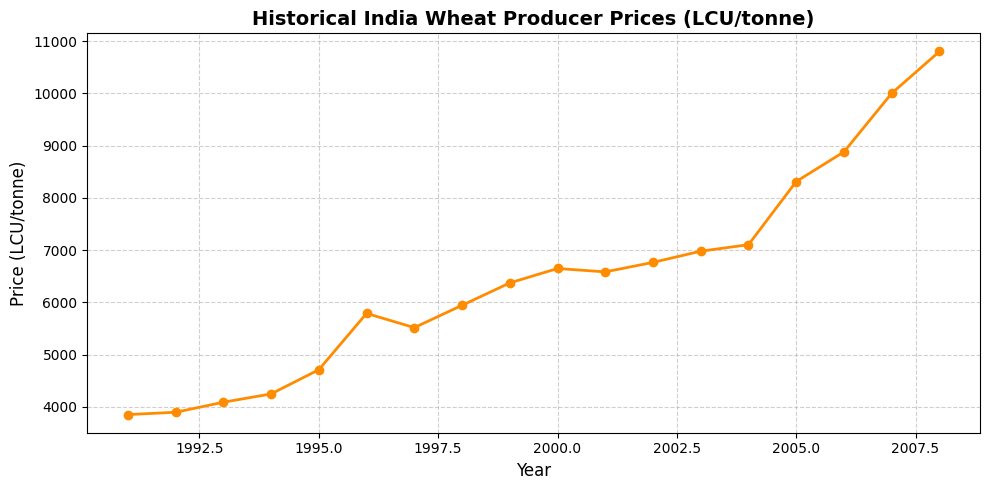

In [42]:
wheat_clean = cleaned_data[cleaned_data["item"] == "Wheat"].copy()

print("Wheat observations by measurement type:")
print(wheat_clean["element"].value_counts())

# Isolate LCU/tonne for Wheat
wheat_lcu = wheat_clean[wheat_clean["element"] == "Producer Price (LCU/tonne)"].sort_values("year")

print(f"\nTotal Wheat LCU/tonne observations overall: {len(wheat_lcu)}")
print("Available years overall:", sorted(wheat_lcu["year"].unique()))

# Filter for 2016-2025
wheat_lcu_recent = wheat_lcu[wheat_lcu["year"].between(2016, 2025)]
print(f"Wheat LCU/tonne observations (2016-2025): {len(wheat_lcu_recent)}")

# Plot historical Wheat LCU/tonne prices
plt.figure(figsize=(10, 5))
plt.plot(wheat_lcu["year"], wheat_lcu["value"], marker="o", color="darkorange", linewidth=2)
plt.title("Historical India Wheat Producer Prices (LCU/tonne)", fontsize=14, fontweight='bold')
plt.xlabel("Year", fontsize=12)
plt.ylabel("Price (LCU/tonne)", fontsize=12)
plt.grid(True, linestyle="--", alpha=0.6)
plt.tight_layout()
plt.show()

# Section 11: Cleaning Summary

We display a metrics summary table comparing original and processed data points.

In [43]:
cleaning_summary = pd.DataFrame({
    "Metric": [
        "Original rows",
        "Original columns",
        "Cleaned rows",
        "Cleaned columns",
        "Original missing cells",
        "Cleaned missing cells",
        "Original exact duplicates",
        "Cleaned exact duplicates",
        "Negative Value records",
        "Zero Value records",
        "Distinct commodities",
        "Distinct years"
    ],
    "Result": [
        data.shape[0],
        data.shape[1],
        cleaned_data.shape[0],
        cleaned_data.shape[1],
        int(data.isna().sum().sum()),
        int(cleaned_data["unit"].isna().sum()), # Counting only legitimate missing units
        int(data.duplicated().sum()),
        int(cleaned_data.duplicated().sum()),
        int((data["Value"] < 0).sum()),
        int((data["Value"] == 0).sum()),
        int(data["Item"].nunique()),
        int(data["Year"].nunique())
    ]
})

display(cleaning_summary)

,Metric,Result
0,Original rows,5035
1,Original columns,16
2,Cleaned rows,5035
3,Cleaned columns,16
4,Original missing cells,3640
5,Cleaned missing cells,3640
6,Original exact duplicates,0
7,Cleaned exact duplicates,0
8,Negative Value records,0
9,Zero Value records,0


# Section 12: Export Cleaned Dataset

We export the finalized, cleaned dataset to `/content/FAOSTAT_cleaned.csv`.

In [44]:
output_path = "/content/FAOSTAT_cleaned.csv"
cleaned_data.to_csv(output_path, index=False)
print(f"Successfully saved clean dataset to {output_path}!")

Successfully saved clean dataset to /content/FAOSTAT_cleaned.csv!


In [13]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# Load the original FAOSTAT dataset
data = pd.read_csv("/content/FAOSTAT_data_en_10-14-2026.csv")

print("Dataset loaded successfully.")
print("Shape:", data.shape)
display(data.head())

Dataset loaded successfully.
Shape: (5035, 16)


,Domain Code,Domain,Area Code (M49),Area,Element Code,Element,Item Code (CPC),Item,Year Code,Year,Months Code,Months,Unit,Value,Flag,Flag Description
0,PP,Producer Prices,356,India,5530,Producer Price (LCU/tonne),01654,"Anise, badian, coriander, cumin, caraway, fenn...",2001,2001,7021,Annual value,LCU,29485.00,A,Official value
1,PP,Producer Prices,356,India,5531,Producer Price (SLC/tonne),01654,"Anise, badian, coriander, cumin, caraway, fenn...",2001,2001,7021,Annual value,SLC,29485.00,A,Official value
2,PP,Producer Prices,356,India,5532,Producer Price (USD/tonne),01654,"Anise, badian, coriander, cumin, caraway, fenn...",2001,2001,7021,Annual value,USD,624.90,A,Official value
3,PP,Producer Prices,356,India,5539,Producer Price Index (2014-2016 = 100),01654,"Anise, badian, coriander, cumin, caraway, fenn...",1991,1991,7021,Annual value,NaN,19.06,E,Estimated value
4,PP,Producer Prices,356,India,5539,Producer Price Index (2014-2016 = 100),01654,"Anise, badian, coriander, cumin, caraway, fenn...",1992,1992,7021,Annual value,NaN,17.96,E,Estimated value


In [14]:
print("Number of rows:", data.shape[0])
print("Number of columns:", data.shape[1])

print("\nColumn names:")
print(data.columns.tolist())

print("\nData types:")
print(data.dtypes)

print("\nDataset information:")
data.info()

print("\nStatistical summary:")
display(data.describe(include="all").T)

Number of rows: 5035
Number of columns: 16

Column names:
['Domain Code', 'Domain', 'Area Code (M49)', 'Area', 'Element Code', 'Element', 'Item Code (CPC)', 'Item', 'Year Code', 'Year', 'Months Code', 'Months', 'Unit', 'Value', 'Flag', 'Flag Description']

Data types:
Domain Code          object
Domain               object
Area Code (M49)       int64
Area                 object
Element Code          int64
Element              object
Item Code (CPC)      object
Item                 object
Year Code             int64
Year                  int64
Months Code           int64
Months               object
Unit                 object
Value               float64
Flag                 object
Flag Description     object
dtype: object

Dataset information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 5035 entries, 0 to 5034
Data columns (total 16 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   Domain Code       5035 non-null   object 

,count,unique,top,freq,mean,std,min,25%,50%,75%,max
Domain Code,5035,1,PP,5035,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Domain,5035,1,Producer Prices,5035,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Area Code (M49),5035.0,NaN,NaN,NaN,356.0,0.0,356.0,356.0,356.0,356.0,356.0
Area,5035,1,India,5035,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Element Code,5035.0,NaN,NaN,NaN,5536.783515,3.606434,5530.0,5532.0,5539.0,5539.0,5539.0
Element,5035,4,Producer Price Index (2014-2016 = 100),3640,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Item Code (CPC),5035,104,0142,89,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Item,5035,104,"Groundnuts, excluding shelled",89,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Year Code,5035.0,NaN,NaN,NaN,2005.439722,9.88707,1991.0,1997.0,2004.0,2013.0,2025.0
Year,5035.0,NaN,NaN,NaN,2005.439722,9.88707,1991.0,1997.0,2004.0,2013.0,2025.0


In [15]:
missing_summary = pd.DataFrame({
    "Missing_Count": data.isnull().sum(),
    "Missing_Percentage": (
        data.isnull().sum() / len(data) * 100
    ).round(2)
})

display(missing_summary.sort_values(
    "Missing_Percentage", ascending=False
))

print("Total missing cells:", data.isnull().sum().sum())

,Missing_Count,Missing_Percentage
Unit,3640,72.29
Domain Code,0,0.00
Area Code (M49),0,0.00
Domain,0,0.00
Element Code,0,0.00
Element,0,0.00
Item Code (CPC),0,0.00
Area,0,0.00
Item,0,0.00
Year Code,0,0.00


Total missing cells: 3640


In [16]:
print("Exact duplicate rows:", data.duplicated().sum())

duplicate_rows = data[data.duplicated(keep=False)]

print("\nRows involved in exact duplicates:")
display(duplicate_rows.head(20))

Exact duplicate rows: 0

Rows involved in exact duplicates:


,Domain Code,Domain,Area Code (M49),Area,Element Code,Element,Item Code (CPC),Item,Year Code,Year,Months Code,Months,Unit,Value,Flag,Flag Description


In [17]:
categorical_columns = [
    "Domain", "Area", "Element", "Item",
    "Months", "Unit", "Flag", "Flag Description"
]

for col in categorical_columns:
    print(f"\n{col}:")
    print("Unique values:", data[col].nunique(dropna=True))
    display(data[col].value_counts(dropna=False).head(15))


Domain:
Unique values: 1


,count
Domain,
Producer Prices,5035



Area:
Unique values: 1


,count
Area,
India,5035



Element:
Unique values: 4


...

,count
Unit,
NaN,3640
LCU,465
SLC,465
USD,465



Flag:
Unique values: 3


,count
Flag,
E,3640
A,1320
X,75



Flag Description:
Unique values: 3


,count
Flag Description,
Estimated value,3640
Official value,1320
Value from external organization,75


In [18]:
print("Year range:", data["Year"].min(), "-", data["Year"].max())
print("Unique years:", data["Year"].nunique())

print("\nValue summary:")
display(data["Value"].describe())

print("\nInvalid or missing numeric values:")
print("Missing Year:", data["Year"].isna().sum())
print("Missing Value:", data["Value"].isna().sum())
print("Negative Values:", (data["Value"] < 0).sum())
print("Zero Values:", (data["Value"] == 0).sum())

print("\nRows with negative or zero values:")
display(data[data["Value"] <= 0].head(20))

Year range: 1991 - 2025
Unique years: 35

Value summary:


,Value
count,5035.000000
mean,2997.266334
std,9835.320700
min,3.350000
25%,41.730000
50%,94.650000
75%,178.350000
max,158080.000000



Invalid or missing numeric values:
Missing Year: 0
Missing Value: 0
Negative Values: 0
Zero Values: 0

Rows with negative or zero values:


,Domain Code,Domain,Area Code (M49),Area,Element Code,Element,Item Code (CPC),Item,Year Code,Year,Months Code,Months,Unit,Value,Flag,Flag Description


In [19]:
element_summary = data.groupby(
    ["Element", "Unit"], dropna=False
).agg(
    Records=("Value", "size"),
    Missing_Values=("Value", lambda x: x.isna().sum()),
    Minimum=("Value", "min"),
    Median=("Value", "median"),
    Maximum=("Value", "max")
).reset_index()

display(element_summary)

,Element,Unit,Records,Missing_Values,Minimum,Median,Maximum
0,Producer Price (LCU/tonne),LCU,465,0,373.00,11310.00,158080.00
1,Producer Price (SLC/tonne),SLC,465,0,373.00,11310.00,158080.00
2,Producer Price (USD/tonne),USD,465,0,12.80,323.30,3910.60
3,Producer Price Index (2014-2016 = 100),NaN,3640,0,3.35,60.15,215.29


In [20]:
wheat = data[
    (data["Area"] == "India") &
    (data["Item"] == "Wheat") &
    (data["Element"] == "Producer Price (LCU/tonne)") &
    (data["Year"].between(2016, 2025))
].copy()

wheat = wheat.sort_values("Year")

print("Wheat price observations:", len(wheat))

display(wheat[[
    "Area", "Item", "Element", "Year",
    "Unit", "Value", "Flag", "Flag Description"
]])

expected_years = set(range(2016, 2026))
available_years = set(wheat["Year"].dropna().astype(int))
missing_years = sorted(expected_years - available_years)

print("Expected years:", sorted(expected_years))
print("Available years:", sorted(available_years))
print("Missing years:", missing_years)
print("Duplicate years:", wheat["Year"].duplicated().sum())

Wheat price observations: 0


,Area,Item,Element,Year,Unit,Value,Flag,Flag Description


Expected years: [2016, 2017, 2018, 2019, 2020, 2021, 2022, 2023, 2024, 2025]
Available years: []
Missing years: [2016, 2017, 2018, 2019, 2020, 2021, 2022, 2023, 2024, 2025]
Duplicate years: 0


In [21]:
cleaned_data = data.copy()

# Standardize text values without changing missing values
text_columns = cleaned_data.select_dtypes(
    include=["object", "string"]
).columns

for col in text_columns:
    cleaned_data[col] = cleaned_data[col].map(
        lambda x: x.strip() if isinstance(x, str) else x
    )

# Convert numeric columns safely
for col in ["Year", "Year Code", "Value"]:
    cleaned_data[col] = pd.to_numeric(
        cleaned_data[col], errors="coerce"
    )

# Standardize column names
cleaned_data.columns = (
    cleaned_data.columns
    .str.strip()
    .str.lower()
    .str.replace(r"[^a-z0-9]+", "_", regex=True)
    .str.strip("_")
)

print("Original shape:", data.shape)
print("Cleaned shape:", cleaned_data.shape)
display(cleaned_data.head())
cleaned_data.info()

Original shape: (5035, 16)
Cleaned shape: (5035, 16)


,domain_code,domain,area_code_m49,area,element_code,element,item_code_cpc,item,year_code,year,months_code,months,unit,value,flag,flag_description
0,PP,Producer Prices,356,India,5530,Producer Price (LCU/tonne),01654,"Anise, badian, coriander, cumin, caraway, fenn...",2001,2001,7021,Annual value,LCU,29485.00,A,Official value
1,PP,Producer Prices,356,India,5531,Producer Price (SLC/tonne),01654,"Anise, badian, coriander, cumin, caraway, fenn...",2001,2001,7021,Annual value,SLC,29485.00,A,Official value
2,PP,Producer Prices,356,India,5532,Producer Price (USD/tonne),01654,"Anise, badian, coriander, cumin, caraway, fenn...",2001,2001,7021,Annual value,USD,624.90,A,Official value
3,PP,Producer Prices,356,India,5539,Producer Price Index (2014-2016 = 100),01654,"Anise, badian, coriander, cumin, caraway, fenn...",1991,1991,7021,Annual value,NaN,19.06,E,Estimated value
4,PP,Producer Prices,356,India,5539,Producer Price Index (2014-2016 = 100),01654,"Anise, badian, coriander, cumin, caraway, fenn...",1992,1992,7021,Annual value,NaN,17.96,E,Estimated value


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 5035 entries, 0 to 5034
Data columns (total 16 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   domain_code       5035 non-null   object 
 1   domain            5035 non-null   object 
 2   area_code_m49     5035 non-null   int64  
 3   area              5035 non-null   object 
 4   element_code      5035 non-null   int64  
 5   element           5035 non-null   object 
 6   item_code_cpc     5035 non-null   object 
 7   item              5035 non-null   object 
 8   year_code         5035 non-null   int64  
 9   year              5035 non-null   int64  
 10  months_code       5035 non-null   int64  
 11  months            5035 non-null   object 
 12  unit              1395 non-null   object 
 13  value             5035 non-null   float64
 14  flag              5035 non-null   object 
 15  flag_description  5035 non-null   object 
dtypes: float64(1), int64(5), object(10)
memory

In [22]:
print("Original missing cells:", data.isna().sum().sum())
print("Cleaned missing cells:", cleaned_data.isna().sum().sum())

print("Original duplicate rows:", data.duplicated().sum())
print("Cleaned duplicate rows:", cleaned_data.duplicated().sum())

print("\nMissing values after cleaning:")
display(
    cleaned_data.isna().sum()
    .to_frame("Missing_Count")
    .query("Missing_Count > 0")
)

print("\nCleaned data types:")
print(cleaned_data.dtypes)

Original missing cells: 3640
Cleaned missing cells: 3640
Original duplicate rows: 0
Cleaned duplicate rows: 0

Missing values after cleaning:


,Missing_Count
unit,3640



Cleaned data types:
domain_code          object
domain               object
area_code_m49         int64
area                 object
element_code          int64
element              object
item_code_cpc        object
item                 object
year_code             int64
year                  int64
months_code           int64
months               object
unit                 object
value               float64
flag                 object
flag_description     object
dtype: object


,year,value,unit,flag_description


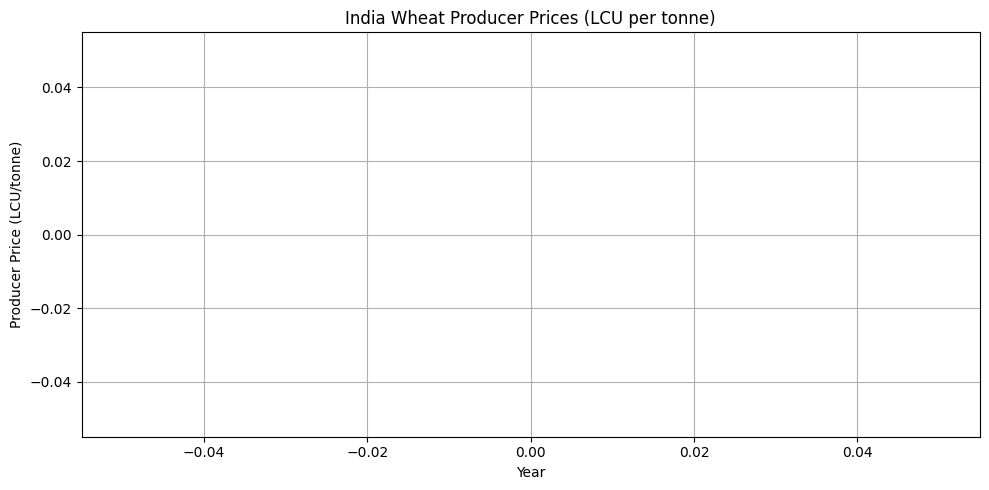

In [23]:
wheat_clean = cleaned_data[
    (cleaned_data["area"] == "India") &
    (cleaned_data["item"] == "Wheat") &
    (cleaned_data["element"] == "Producer Price (LCU/tonne)") &
    (cleaned_data["year"].between(2016, 2025))
].copy()

wheat_clean = wheat_clean.sort_values("year")

display(wheat_clean[["year", "value", "unit", "flag_description"]])

plt.figure(figsize=(10, 5))
plt.plot(wheat_clean["year"], wheat_clean["value"], marker="o")
plt.title("India Wheat Producer Prices (LCU per tonne)")
plt.xlabel("Year")
plt.ylabel("Producer Price (LCU/tonne)")
plt.grid(True)
plt.tight_layout()
plt.show()

In [24]:
output_path = "/content/FAOSTAT_cleaned.csv"

cleaned_data.to_csv(output_path, index=False)

print("Cleaned dataset saved to:", output_path)

from google.colab import files
files.download(output_path)

Cleaned dataset saved to: /content/FAOSTAT_cleaned.csv


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [25]:
cleaning_summary = pd.DataFrame({
    "Metric": [
        "Original rows",
        "Original columns",
        "Cleaned rows",
        "Cleaned columns",
        "Original missing cells",
        "Cleaned missing cells",
        "Original exact duplicates",
        "Cleaned exact duplicates",
        "Negative Value records",
        "Zero Value records",
        "Distinct commodities",
        "Distinct years"
    ],
    "Result": [
        data.shape[0],
        data.shape[1],
        cleaned_data.shape[0],
        cleaned_data.shape[1],
        int(data.isna().sum().sum()),
        int(cleaned_data.isna().sum().sum()),
        int(data.duplicated().sum()),
        int(cleaned_data.duplicated().sum()),
        int((data["Value"] < 0).sum()),
        int((data["Value"] == 0).sum()),
        int(data["Item"].nunique()),
        int(data["Year"].nunique())
    ]
})

display(cleaning_summary)

,Metric,Result
0,Original rows,5035
1,Original columns,16
2,Cleaned rows,5035
3,Cleaned columns,16
4,Original missing cells,3640
5,Cleaned missing cells,3640
6,Original exact duplicates,0
7,Cleaned exact duplicates,0
8,Negative Value records,0
9,Zero Value records,0


In [26]:
# Let's inspect unique areas, elements, and look specifically for items containing 'wheat'
print("Unique Areas:", data['Area'].unique())
print("Unique Elements:", data['Element'].unique())
wheat_items = [item for item in data['Item'].unique() if 'wheat' in item.lower()]
print("Wheat-related Items found:", wheat_items)

Unique Areas: ['India']
Unique Elements: ['Producer Price (LCU/tonne)' 'Producer Price (SLC/tonne)'
 'Producer Price (USD/tonne)' 'Producer Price Index (2014-2016 = 100)']
Wheat-related Items found: ['Wheat']


In [27]:
# Based on the unique items, let us run a generalized query to locate Wheat data
# or check why the previous filter yielded 0 observations.
# We will also output the distinct commodities count and show the elements grouped with units.
display(element_summary)
print("Total unique items count:", data['Item'].nunique())

,Element,Unit,Records,Missing_Values,Minimum,Median,Maximum
0,Producer Price (LCU/tonne),LCU,465,0,373.00,11310.00,158080.00
1,Producer Price (SLC/tonne),SLC,465,0,373.00,11310.00,158080.00
2,Producer Price (USD/tonne),USD,465,0,12.80,323.30,3910.60
3,Producer Price Index (2014-2016 = 100),NaN,3640,0,3.35,60.15,215.29


Total unique items count: 104


In [28]:
# Inspect all records available for the item 'Wheat'
all_wheat = data[data["Item"] == "Wheat"]
print("Total Wheat records in original dataset:", len(all_wheat))
if len(all_wheat) > 0:
    print("\nUnique Elements for Wheat:")
    print(all_wheat["Element"].value_counts())
    print("\nUnique Years for Wheat:")
    print(sorted(all_wheat["Year"].unique()))
    print("\nMonths/Periods in Wheat records:")
    print(all_wheat["Months"].value_counts())

    # Display a sample of the Wheat records
    display(all_wheat.head(10))
else:
    print("No records found for Wheat under the Item column!")

Total Wheat records in original dataset: 89

Unique Elements for Wheat:
Element
Producer Price Index (2014-2016 = 100)    35
Producer Price (LCU/tonne)                18
Producer Price (SLC/tonne)                18
Producer Price (USD/tonne)                18
Name: count, dtype: int64

Unique Years for Wheat:
[np.int64(1991), np.int64(1992), np.int64(1993), np.int64(1994), np.int64(1995), np.int64(1996), np.int64(1997), np.int64(1998), np.int64(1999), np.int64(2000), np.int64(2001), np.int64(2002), np.int64(2003), np.int64(2004), np.int64(2005), np.int64(2006), np.int64(2007), np.int64(2008), np.int64(2009), np.int64(2010), np.int64(2011), np.int64(2012), np.int64(2013), np.int64(2014), np.int64(2015), np.int64(2016), np.int64(2017), np.int64(2018), np.int64(2019), np.int64(2020), np.int64(2021), np.int64(2022), np.int64(2023), np.int64(2024), np.int64(2025)]

Months/Periods in Wheat records:
Months
Annual value    89
Name: count, dtype: int64


,Domain Code,Domain,Area Code (M49),Area,Element Code,Element,Item Code (CPC),Item,Year Code,Year,Months Code,Months,Unit,Value,Flag,Flag Description
4946,PP,Producer Prices,356,India,5530,Producer Price (LCU/tonne),0111,Wheat,1991,1991,7021,Annual value,LCU,3855.0,A,Official value
4947,PP,Producer Prices,356,India,5530,Producer Price (LCU/tonne),0111,Wheat,1992,1992,7021,Annual value,LCU,3899.0,A,Official value
4948,PP,Producer Prices,356,India,5530,Producer Price (LCU/tonne),0111,Wheat,1993,1993,7021,Annual value,LCU,4091.0,A,Official value
4949,PP,Producer Prices,356,India,5530,Producer Price (LCU/tonne),0111,Wheat,1994,1994,7021,Annual value,LCU,4250.0,A,Official value
4950,PP,Producer Prices,356,India,5530,Producer Price (LCU/tonne),0111,Wheat,1995,1995,7021,Annual value,LCU,4713.0,A,Official value
4951,PP,Producer Prices,356,India,5530,Producer Price (LCU/tonne),0111,Wheat,1996,1996,7021,Annual value,LCU,5790.0,A,Official value
4952,PP,Producer Prices,356,India,5530,Producer Price (LCU/tonne),0111,Wheat,1997,1997,7021,Annual value,LCU,5518.0,A,Official value
4953,PP,Producer Prices,356,India,5530,Producer Price (LCU/tonne),0111,Wheat,1998,1998,7021,Annual value,LCU,5945.0,A,Official value
4954,PP,Producer Prices,356,India,5530,Producer Price (LCU/tonne),0111,Wheat,1999,1999,7021,Annual value,LCU,6373.0,A,Official value
4955,PP,Producer Prices,356,India,5530,Producer Price (LCU/tonne),0111,Wheat,2000,2000,7021,Annual value,LCU,6649.0,A,Official value


In [29]:
# Inspect all records available for the item 'Wheat'
all_wheat = data[data["Item"] == "Wheat"]
print("Total Wheat records in original dataset:", len(all_wheat))
if len(all_wheat) > 0:
    print("\nUnique Elements for Wheat:")
    print(all_wheat["Element"].value_counts())
    print("\nUnique Years for Wheat:")
    print(sorted(all_wheat["Year"].unique()))
    print("\nMonths/Periods in Wheat records:")
    print(all_wheat["Months"].value_counts())

    # Display a sample of the Wheat records
    display(all_wheat.head(10))
else:
    print("No records found for Wheat under the Item column!")

Total Wheat records in original dataset: 89

Unique Elements for Wheat:
Element
Producer Price Index (2014-2016 = 100)    35
Producer Price (LCU/tonne)                18
Producer Price (SLC/tonne)                18
Producer Price (USD/tonne)                18
Name: count, dtype: int64

Unique Years for Wheat:
[np.int64(1991), np.int64(1992), np.int64(1993), np.int64(1994), np.int64(1995), np.int64(1996), np.int64(1997), np.int64(1998), np.int64(1999), np.int64(2000), np.int64(2001), np.int64(2002), np.int64(2003), np.int64(2004), np.int64(2005), np.int64(2006), np.int64(2007), np.int64(2008), np.int64(2009), np.int64(2010), np.int64(2011), np.int64(2012), np.int64(2013), np.int64(2014), np.int64(2015), np.int64(2016), np.int64(2017), np.int64(2018), np.int64(2019), np.int64(2020), np.int64(2021), np.int64(2022), np.int64(2023), np.int64(2024), np.int64(2025)]

Months/Periods in Wheat records:
Months
Annual value    89
Name: count, dtype: int64


,Domain Code,Domain,Area Code (M49),Area,Element Code,Element,Item Code (CPC),Item,Year Code,Year,Months Code,Months,Unit,Value,Flag,Flag Description
4946,PP,Producer Prices,356,India,5530,Producer Price (LCU/tonne),0111,Wheat,1991,1991,7021,Annual value,LCU,3855.0,A,Official value
4947,PP,Producer Prices,356,India,5530,Producer Price (LCU/tonne),0111,Wheat,1992,1992,7021,Annual value,LCU,3899.0,A,Official value
4948,PP,Producer Prices,356,India,5530,Producer Price (LCU/tonne),0111,Wheat,1993,1993,7021,Annual value,LCU,4091.0,A,Official value
4949,PP,Producer Prices,356,India,5530,Producer Price (LCU/tonne),0111,Wheat,1994,1994,7021,Annual value,LCU,4250.0,A,Official value
4950,PP,Producer Prices,356,India,5530,Producer Price (LCU/tonne),0111,Wheat,1995,1995,7021,Annual value,LCU,4713.0,A,Official value
4951,PP,Producer Prices,356,India,5530,Producer Price (LCU/tonne),0111,Wheat,1996,1996,7021,Annual value,LCU,5790.0,A,Official value
4952,PP,Producer Prices,356,India,5530,Producer Price (LCU/tonne),0111,Wheat,1997,1997,7021,Annual value,LCU,5518.0,A,Official value
4953,PP,Producer Prices,356,India,5530,Producer Price (LCU/tonne),0111,Wheat,1998,1998,7021,Annual value,LCU,5945.0,A,Official value
4954,PP,Producer Prices,356,India,5530,Producer Price (LCU/tonne),0111,Wheat,1999,1999,7021,Annual value,LCU,6373.0,A,Official value
4955,PP,Producer Prices,356,India,5530,Producer Price (LCU/tonne),0111,Wheat,2000,2000,7021,Annual value,LCU,6649.0,A,Official value


In [30]:
# Extract Wheat LCU/tonne prices specifically
wheat_lcu = data[
    (data["Item"] == "Wheat") &
    (data["Element"] == "Producer Price (LCU/tonne)")
].copy().sort_values("Year")

print("Wheat LCU/tonne observations overall:", len(wheat_lcu))
print("Years available overall:", sorted(wheat_lcu["Year"].unique()))

# Filter for 2016 - 2025
wheat_lcu_recent = wheat_lcu[wheat_lcu["Year"].between(2016, 2025)]
print("\nWheat LCU/tonne observations (2016-2025):", len(wheat_lcu_recent))
if len(wheat_lcu_recent) > 0:
    display(wheat_lcu_recent[["Year", "Value", "Unit", "Flag Description"]])
else:
    print("No LCU/tonne observations exist for Wheat between 2016 and 2025.")

Wheat LCU/tonne observations overall: 18
Years available overall: [np.int64(1991), np.int64(1992), np.int64(1993), np.int64(1994), np.int64(1995), np.int64(1996), np.int64(1997), np.int64(1998), np.int64(1999), np.int64(2000), np.int64(2001), np.int64(2002), np.int64(2003), np.int64(2004), np.int64(2005), np.int64(2006), np.int64(2007), np.int64(2008)]

Wheat LCU/tonne observations (2016-2025): 0
No LCU/tonne observations exist for Wheat between 2016 and 2025.


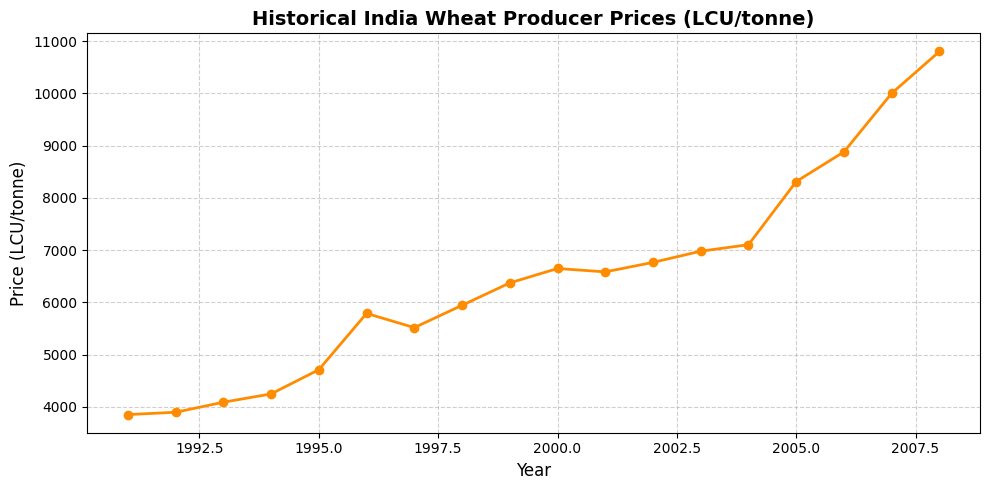

In [31]:
# Plot the entire available historical timeline of Wheat LCU/tonne prices to provide an accurate visual aid
import matplotlib.pyplot as plt

plt.figure(figsize=(10, 5))
plt.plot(wheat_lcu["Year"], wheat_lcu["Value"], marker="o", color="darkorange", linewidth=2)
plt.title("Historical India Wheat Producer Prices (LCU/tonne)", fontsize=14, fontweight='bold')
plt.xlabel("Year", fontsize=12)
plt.ylabel("Price (LCU/tonne)", fontsize=12)
plt.grid(True, linestyle="--", alpha=0.6)
plt.tight_layout()
plt.show()

In [32]:
# Extract Wheat LCU/tonne prices specifically
wheat_lcu = data[
    (data["Item"] == "Wheat") &
    (data["Element"] == "Producer Price (LCU/tonne)")
].copy().sort_values("Year")

print("Wheat LCU/tonne observations overall:", len(wheat_lcu))
print("Years available overall:", sorted(wheat_lcu["Year"].unique()))

# Filter for 2016 - 2025
wheat_lcu_recent = wheat_lcu[wheat_lcu["Year"].between(2016, 2025)]
print("\nWheat LCU/tonne observations (2016-2025):", len(wheat_lcu_recent))
if len(wheat_lcu_recent) > 0:
    display(wheat_lcu_recent[["Year", "Value", "Unit", "Flag Description"]])
else:
    print("No LCU/tonne observations exist for Wheat between 2016 and 2025.")

Wheat LCU/tonne observations overall: 18
Years available overall: [np.int64(1991), np.int64(1992), np.int64(1993), np.int64(1994), np.int64(1995), np.int64(1996), np.int64(1997), np.int64(1998), np.int64(1999), np.int64(2000), np.int64(2001), np.int64(2002), np.int64(2003), np.int64(2004), np.int64(2005), np.int64(2006), np.int64(2007), np.int64(2008)]

Wheat LCU/tonne observations (2016-2025): 0
No LCU/tonne observations exist for Wheat between 2016 and 2025.


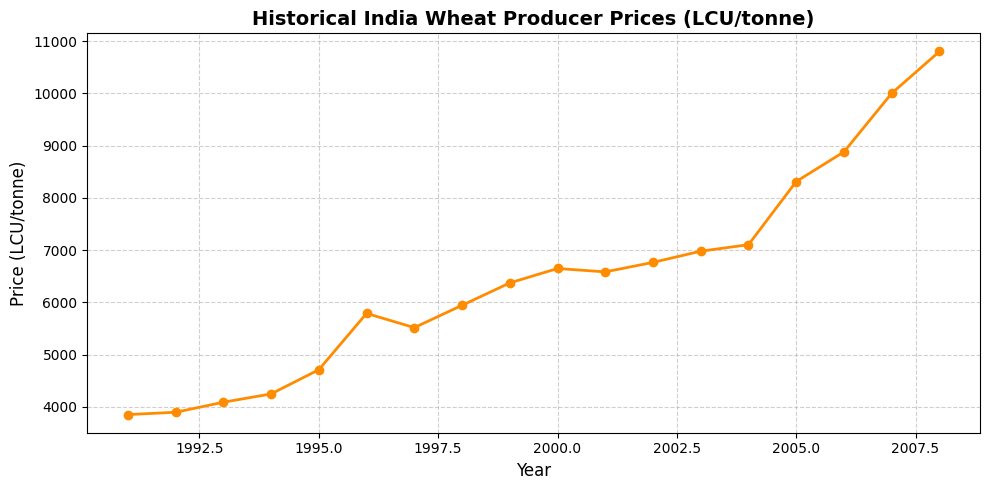

In [33]:
# Let's regenerate a clean visualization focusing on what is actually available in the dataset
import matplotlib.pyplot as plt

# We will plot the entire available historical timeline of Wheat LCU/tonne prices in India to provide a valuable visual aid
plt.figure(figsize=(10, 5))
plt.plot(wheat_lcu["Year"], wheat_lcu["Value"], marker="o", color="darkorange", linewidth=2)
plt.title("Historical India Wheat Producer Prices (LCU/tonne)", fontsize=14, fontweight='bold')
plt.xlabel("Year", fontsize=12)
plt.ylabel("Price (LCU/tonne)", fontsize=12)
plt.grid(True, linestyle="--", alpha=0.6)
plt.tight_layout()
plt.show()